# 05. Deblurring（ブレ除去）と Denoising（ノイズ除去）

**セミナー対応章**：第3章（3）　｜　**推奨ランタイム**：Colab無料枠 T4 GPU（CPUでも可・遅い）　｜　**所要時間**：約3分

1. 手ブレの数理：**点拡がり関数（PSF）** との畳み込み
2. 古典：Wiener Filter → **AI を組み込んだ反復復元（DPIR：Plug-and-Play）**
3. 暗所の **センサーノイズ**（信号依存のポアソン＋読み出しノイズ）を作る
4. NLM（古典）/ DRUNet / SCUNet（実ノイズ向けの Transformer+CNN）で除去
5. **過度な平滑化** を防ぐ工夫（ノイズを少し戻す）

In [1]:
# ===== 共通セットアップ（このセルを最初に1回だけ実行してください） =====
import os, sys, subprocess, time, urllib.request

IN_COLAB = "google.colab" in sys.modules

def pip_install(*pkgs):
    """足りないライブラリを静かにインストールする（Colab用）"""
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)

if IN_COLAB:
    # Colabには torch / transformers / diffusers などが最初から入っています。
    # 不足分だけ追加します（1〜2分）。
    pip_install("spandrel", "lpips", "diffusers>=0.30", "accelerate", "peft")

import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
print(f"実行環境: {'Google Colab' if IN_COLAB else 'ローカルPC'} / torch {torch.__version__}")
if DEVICE == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name}  VRAM: {p.total_memory / 1024**3:.1f} GB")
else:
    print("GPUが見つかりません。Colabでは［ランタイム］→［ランタイムのタイプを変更］→ T4 GPU を選んでください。")

WEIGHTS_DIR = os.path.abspath("weights")
os.makedirs(WEIGHTS_DIR, exist_ok=True)

def download(url, name=None):
    """学習済み重みをダウンロード（2回目以降はキャッシュを使う）"""
    path = os.path.join(WEIGHTS_DIR, name or url.split("/")[-1])
    if not os.path.exists(path):
        print("downloading", url)
        urllib.request.urlretrieve(url, path)
    return path

def load_sample(name="astronaut", size=None):
    """scikit-image同梱のサンプル画像（ネット不要）。name: astronaut / coffee / chelsea / rocket"""
    from skimage import data
    img = Image.fromarray(getattr(data, name)()).convert("RGB")
    if size:
        img = img.resize((size, size) if isinstance(size, int) else size, Image.BICUBIC)
    return img

def load_portrait():
    """顔が大きく写った 512x512 の高画質画像（Kodak 標準テスト画像 kodim04 の上部を切り出し）。
    Kodak 画像は画像処理の評価用に広く使われているフリーのテスト画像（r0k.us/graphics/kodak/）。
    ダウンロードできない場合は astronaut で代用。"""
    try:
        img = Image.open(download("https://r0k.us/graphics/kodak/kodak/kodim04.png")).convert("RGB")
        return img.crop((0, 160, 512, 672))
    except Exception as e:
        print("kodim04 を取得できなかったため astronaut を使います:", e)
        return load_sample("astronaut")

def to_np(img):
    """PIL → float32 [0,1] の (H,W,3) 配列"""
    return np.asarray(img.convert("RGB"), dtype=np.float32) / 255.0

def to_pil(arr):
    return Image.fromarray((np.clip(arr, 0, 1) * 255 + 0.5).astype(np.uint8))

def to_tensor(img):
    """PIL / ndarray → (1,3,H,W) テンソル"""
    a = to_np(img) if isinstance(img, Image.Image) else img
    return torch.from_numpy(np.ascontiguousarray(a, dtype=np.float32)).permute(2, 0, 1)[None].contiguous()

def tensor_to_pil(t):
    return to_pil(t[0].detach().float().clamp(0, 1).permute(1, 2, 0).cpu().numpy())

def psnr(a, b):
    a, b = to_np(a) if isinstance(a, Image.Image) else a, to_np(b) if isinstance(b, Image.Image) else b
    return 10 * np.log10(1.0 / np.mean((a - b) ** 2))

def ssim(a, b):
    from skimage.metrics import structural_similarity
    a, b = to_np(a) if isinstance(a, Image.Image) else a, to_np(b) if isinstance(b, Image.Image) else b
    return structural_similarity(a, b, channel_axis=2, data_range=1.0)

def show(images, titles=None, size=4, rows=1):
    """画像を横に並べて表示（タイトルは文字化け防止のため英数字推奨）"""
    n = len(images)
    cols = (n + rows - 1) // rows
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < n:
            im = images[i]
            if isinstance(im, np.ndarray) and im.ndim == 2:
                ax.imshow(im, cmap="gray")                      # 2次元配列（マップ・スペクトル）は自動スケール
            else:
                if isinstance(im, np.ndarray) and im.dtype != np.uint8:
                    im = np.clip(im, 0, 1)                      # float 画像は 0〜1 に収める
                ax.imshow(im)
            if titles:
                ax.set_title(titles[i], fontsize=11)
    plt.tight_layout()
    plt.show()

def gpu_mem():
    if DEVICE == "cuda":
        print(f"GPUメモリ使用量(ピーク): {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB")

実行環境: ローカルPC / torch 2.11.0+cu128
GPU: NVIDIA GeForce RTX 5090 Laptop GPU  VRAM: 23.9 GB


## 1. 手ブレ PSF と劣化画像

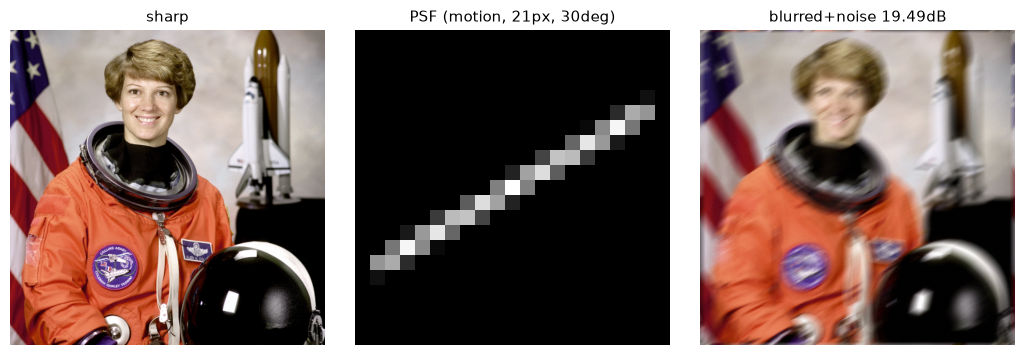

In [2]:
import cv2
import spandrel

def motion_psf(length=21, angle=30):
    k = np.zeros((length, length), np.float32)
    k[length // 2, :] = 1.0
    M = cv2.getRotationMatrix2D((length / 2 - 0.5, length / 2 - 0.5), angle, 1.0)
    k = cv2.warpAffine(k, M, (length, length))
    return k / k.sum()

def psf2otf(k, shape):
    pad = np.zeros(shape, np.float32)
    pad[:k.shape[0], :k.shape[1]] = k
    pad = np.roll(pad, (-(k.shape[0] // 2), -(k.shape[1] // 2)), axis=(0, 1))
    return np.fft.fft2(pad)

def conv_fft(x, K):   # 周期境界の畳み込み（PSFの数理モデルそのもの）
    return np.stack([np.real(np.fft.ifft2(np.fft.fft2(x[..., c]) * K)) for c in range(3)], -1)

rng = np.random.default_rng(0)
x = to_np(load_sample("astronaut"))
k = motion_psf(21, 30)
K = psf2otf(k, x.shape[:2])
sigma_n = 0.01
y = np.clip(conv_fft(x, K) + rng.normal(0, sigma_n, x.shape), 0, 1)
show([x, k, y], ["sharp", "PSF (motion, 21px, 30deg)", f"blurred+noise {psnr(y, x):.2f}dB"], size=3.5)

## 2. Wiener Filter vs DPIR（Deep Plug-and-Play Image Restoration）
DPIR は「PSF を使った物理的なデータ整合ステップ」と「AI デノイザ（DRUNet）による“自然画像らしさ”ステップ」を交互に繰り返します。
**物理モデル × 学習済み事前分布** の組み合わせは、拡散モデルによる復元（DPS, DiffBIR など）にも通じる考え方です。

DPIR: 1.6s


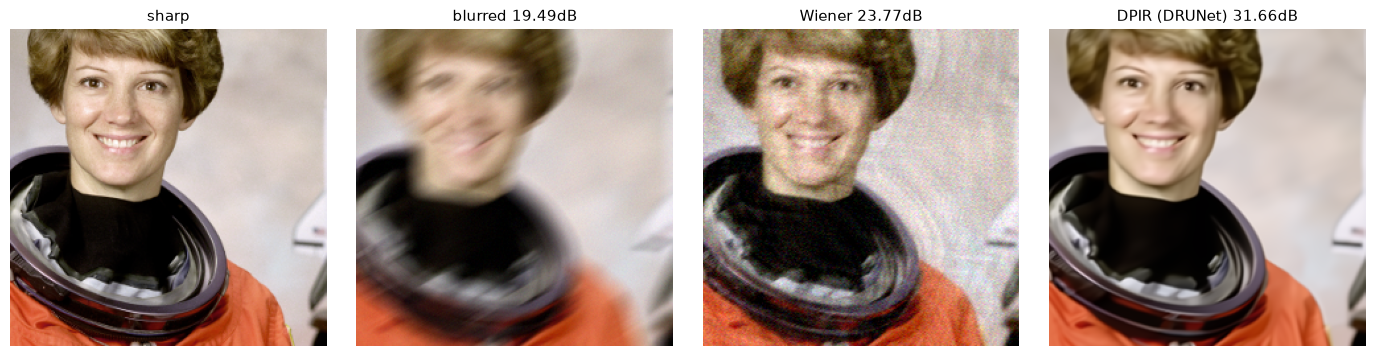

In [3]:
def wiener(y, K, lam=1e-2):
    H = np.conj(K) / (np.abs(K) ** 2 + lam)
    return conv_fft(y, H)

drunet = spandrel.ModelLoader().load_from_file(
    download("https://github.com/cszn/KAIR/releases/download/v1.0/drunet_color.pth")).to(DEVICE).eval()

@torch.no_grad()
def drunet_denoise(img_np, sigma):
    """DRUNet はノイズレベル sigma をもう1チャンネルとして受け取る"""
    t = to_tensor(img_np).to(DEVICE)
    _, _, H, W = t.shape
    ph, pw = (8 - H % 8) % 8, (8 - W % 8) % 8
    t = torch.nn.functional.pad(t, (0, pw, 0, ph), mode="replicate")
    nm = torch.full_like(t[:, :1], sigma)
    out = drunet.model(torch.cat([t, nm], 1))[:, :, :H, :W]
    return out[0].clamp(0, 1).permute(1, 2, 0).cpu().numpy()

def dpir_deblur(y, K, sigma_n, iters=8, lam=0.23):
    sigmas = np.geomspace(49 / 255, max(sigma_n, 1e-3), iters)
    FK, FY = K, np.stack([np.fft.fft2(y[..., c]) for c in range(3)], -1)
    z = y.copy()
    for s in sigmas:
        rho = lam * sigma_n**2 / s**2
        FZ = np.stack([np.fft.fft2(z[..., c]) for c in range(3)], -1)
        X = (np.conj(FK)[..., None] * FY + rho * FZ) / (np.abs(FK)[..., None] ** 2 + rho)   # データ整合（PSF）
        xk = np.real(np.stack([np.fft.ifft2(X[..., c]) for c in range(3)], -1))
        z = drunet_denoise(np.clip(xk, 0, 1), s)                                         # AIデノイザ（事前分布）
    return z

w = np.clip(wiener(y, K, 5e-3), 0, 1)
t = time.time()
d = dpir_deblur(y, K, sigma_n)
print(f"DPIR: {time.time()-t:.1f}s")
crop = (slice(60, 300), slice(140, 380))
show([x[crop], y[crop], w[crop], d[crop]],
     ["sharp", f"blurred {psnr(y,x):.2f}dB", f"Wiener {psnr(w,x):.2f}dB", f"DPIR (DRUNet) {psnr(d,x):.2f}dB"], size=3.5)

### ① データ整合ステップの中身：周波数ごとに「観測」と「AI の推定」を混ぜる
① では「ブレさせると観測 y に一致し、かつ ② の AI の結果 z にも近い画像 x」を求めます：min ‖y − k∗x‖² + ρ‖x − z‖²。
畳み込みはフーリエ変換すると掛け算になるので、周波数ごとに一度で解けて X = (K̄Y + ρZ)/(|K|² + ρ)。これは次のように書き直せます。

**X = w · (Y / K) + (1 − w) · Z、　w = |K|² / (|K|² + ρ)**

- ブレで **消えなかった** 周波数（|K| が大きい）：w ≈ 1 → 観測 Y を PSF で割り戻した値（逆畳み込み）を使う
- ブレで **消えた** 周波数（|K| ≈ 0）：w ≈ 0 → 観測からは戻せないので、② の AI が描いた z の値で埋める
- z = 0 とすると X = K̄Y / (|K|² + ρ) ＝ **Wiener フィルタ**（消えた周波数を 0 で埋める）

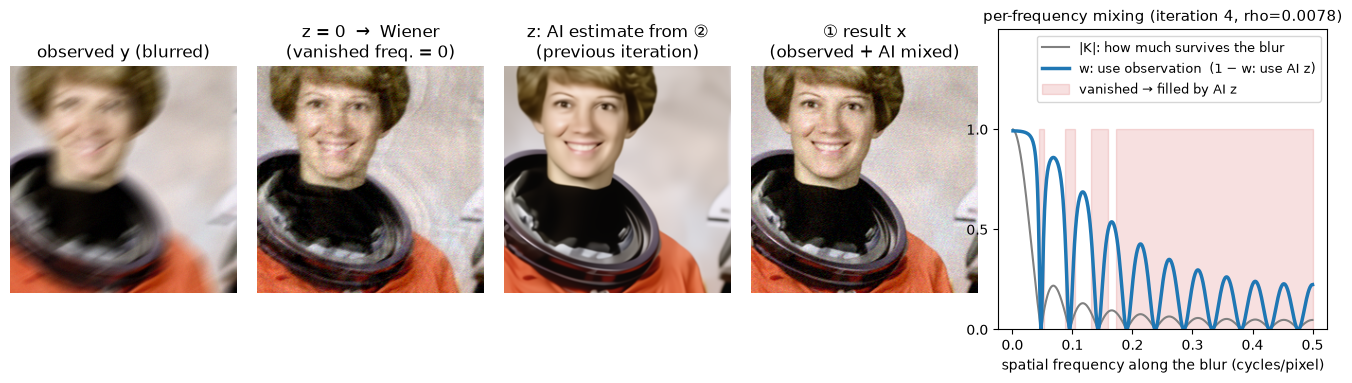

In [4]:
it_show = 3                                          # 4 回目の反復を取り出して見る
sigmas = np.geomspace(49 / 255, max(sigma_n, 1e-3), 8)
FY = np.stack([np.fft.fft2(y[..., c]) for c in range(3)], -1)
z = y.copy()
for i, s in enumerate(sigmas[:it_show + 1]):
    rho = 0.23 * sigma_n**2 / s**2
    FZ = np.stack([np.fft.fft2(z[..., c]) for c in range(3)], -1)
    Wt = (np.abs(K) ** 2 / (np.abs(K) ** 2 + rho))[..., None]                   # 周波数ごとの「観測の信頼度」w
    X = Wt * FY / np.where(np.abs(K) < 1e-8, 1e-8, K)[..., None] + (1 - Wt) * FZ   # = (K̄Y + ρZ)/(|K|²+ρ)
    xk = np.real(np.stack([np.fft.ifft2(X[..., c]) for c in range(3)], -1))
    if i == it_show:
        z_prev = z
        x_wiener = np.real(np.stack([np.fft.ifft2(Wt[..., 0] * FY[..., c] / np.where(np.abs(K) < 1e-8, 1e-8, K)) for c in range(3)], -1))  # z = 0
    z = drunet_denoise(np.clip(xk, 0, 1), s)

fig = plt.figure(figsize=(17, 3.9))
gs = fig.add_gridspec(1, 5, width_ratios=[1, 1, 1, 1, 1.45], wspace=0.08)
ims = [(y, "observed y (blurred)"), (x_wiener, "z = 0  →  Wiener\n(vanished freq. = 0)"),
       (z_prev, "z: AI estimate from ②\n(previous iteration)"), (xk, "① result x\n(observed + AI mixed)")]
for j, (im, tt) in enumerate(ims):
    ax = fig.add_subplot(gs[0, j]); ax.imshow(np.clip(im[crop], 0, 1)); ax.set_title(tt, fontsize=12); ax.axis("off")
ax = fig.add_subplot(gs[0, 4])
f = np.linspace(0.001, 0.5, 600)
Kf = np.abs(np.sin(np.pi * f * 21) / (21 * np.sin(np.pi * f)))              # 長さ 21 画素の手ブレの周波数応答（ブレの方向）
rho = 0.23 * sigma_n**2 / sigmas[it_show] ** 2
ax.plot(f, Kf, color="gray", lw=1.5, label="|K|: how much survives the blur")
ax.plot(f, Kf**2 / (Kf**2 + rho), color="#1f77b4", lw=2.5, label="w: use observation  (1 − w: use AI z)")
ax.fill_between(f, 0, 1, where=Kf**2 / (Kf**2 + rho) < 0.5, color="#C00000", alpha=0.12, label="vanished → filled by AI z")
ax.set_xlabel("spatial frequency along the blur (cycles/pixel)"); ax.set_ylim(0, 1.5); ax.set_yticks([0, 0.5, 1]); ax.legend(fontsize=9.5, loc="upper right")
ax.set_title(f"per-frequency mixing (iteration {it_show + 1}, rho={rho:.4f})", fontsize=11)
plt.show()

> **PSF が未知の場合（ブラインド・デブラー）** は、PSF とシャープ画像を同時に推定する必要があり難易度が上がります。
> 最近は PSF を明示的に推定せず、ブレ画像→シャープ画像を直接学習した Restormer・NAFNet・FFTformer などが主流です（ComfyUI / spandrel でも利用可能）。

## 3. 暗所のセンサーノイズを作る
実際のカメラノイズは **信号依存** です。光子数のゆらぎ（ポアソン分布：明るいほど大きいが相対的には小さい）＋ 読み出しノイズ（ガウス）＋ ゲイン（ISO感度）。
暗い部分ほど S/N 比が悪くなり、さらにデモザイク・JPEG で空間的に相関したノイズになります。

In [5]:
def low_light_noise(x, photons=60, read=0.015, seed=0):
    r = np.random.default_rng(seed)
    dark = x * 0.25                                         # 露出不足
    shot = r.poisson(dark * photons) / photons              # ショットノイズ（信号依存）
    noisy = shot + r.normal(0, read, x.shape)               # 読み出しノイズ
    noisy = noisy * 4.0                                     # ゲイン（ISOを上げて明るくする）
    noisy = cv2.GaussianBlur(noisy.astype(np.float32), (3, 3), 0.6)   # デモザイク等による空間相関
    return np.clip(noisy, 0, 1).astype(np.float32)

xn = low_light_noise(x)
print(f"noisy PSNR: {psnr(xn, x):.2f} dB")

noisy PSNR: 21.02 dB


## 4. ノイズ除去手法の比較

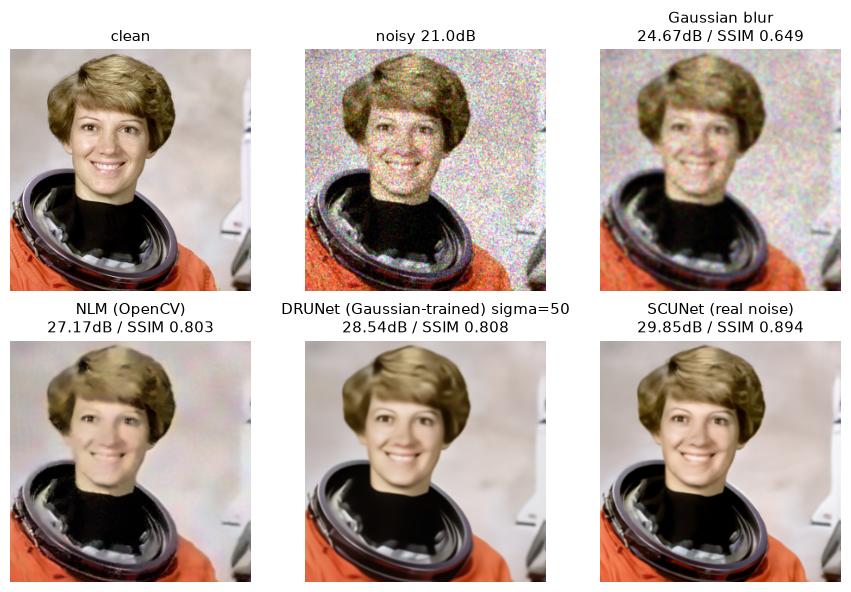

In [6]:
scunet = spandrel.ModelLoader().load_from_file(
    download("https://github.com/cszn/KAIR/releases/download/v1.0/scunet_color_real_psnr.pth")).to(DEVICE).eval()

@torch.no_grad()
def run_model(m, img_np):
    return m(to_tensor(img_np).to(DEVICE))[0].clamp(0, 1).permute(1, 2, 0).cpu().numpy()

u8 = (xn * 255).astype(np.uint8)
res = {
    "Gaussian blur": cv2.GaussianBlur(xn, (0, 0), 1.5),
    "NLM (OpenCV)": cv2.fastNlMeansDenoisingColored(u8, None, 15, 15, 7, 21).astype(np.float32) / 255,
    "DRUNet (Gaussian-trained) sigma=50": drunet_denoise(xn, 50 / 255),
    "SCUNet (real noise)": run_model(scunet, xn),
}
crop = (slice(10, 290), slice(110, 390))   # 顔を含む領域（肌のきめ・髪・服の質感を比較）
show([x[crop], xn[crop]] + [v[crop] for v in res.values()],
     ["clean", f"noisy {psnr(xn,x):.1f}dB"] + [f"{k}\n{psnr(v,x):.2f}dB / SSIM {ssim(v,x):.3f}" for k, v in res.items()],
     size=3, rows=2)

## 5. 過度な平滑化（のっぺり感）を防ぐ
デノイザの強さ（sigma）を上げすぎると、ノイズと一緒に **肌のきめ・布の織り目** まで消えます。
実務の簡単な対策：①ノイズレベルを適切に推定する ②出力に元画像を少し混ぜ戻す（ノイズ再付加）③ノイズ除去後に拡散モデルで質感を再生成する（DiffBIR の2段階構成）。

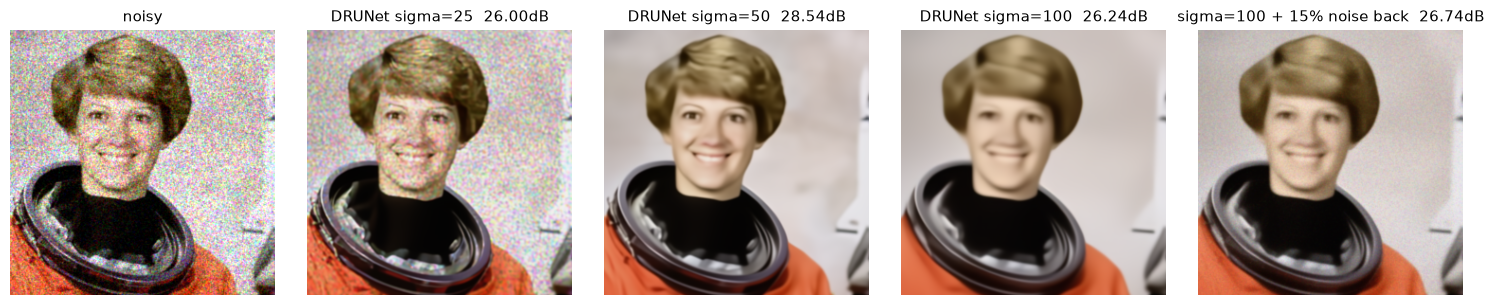

In [7]:
outs = {s: drunet_denoise(xn, s / 255) for s in (25, 50, 100)}
blend = 0.85 * outs[100] + 0.15 * xn
show([xn[crop]] + [v[crop] for v in outs.values()] + [blend[crop]],
     ["noisy"] + [f"DRUNet sigma={s}  {psnr(v,x):.2f}dB" for s, v in outs.items()] + [f"sigma=100 + 15% noise back  {psnr(blend,x):.2f}dB"],
     size=3)

## まとめ
- ブレは「PSF との畳み込み」。PSF が分かれば **物理モデル＋AI事前分布（DPIR）** が強力
- 実ノイズは信号依存・空間相関あり → ガウスノイズで学習したモデルは実写で性能が落ちる。**実ノイズ用モデル（SCUNet 等）** を選ぶ
- 強すぎる除去はディテール喪失。ノイズの混ぜ戻しや、生成モデルでの質感再生成で調整する